# Pemodelan Dual-Guardrail & Evaluasi Triage Klaim INA-CBG (JAGA-KODE)

Notebook ini mendokumentasikan alur kerja pengolahan data, pembentukan profil kelompok rumah sakit sebaya (*Peer Group*), pengujian aturan klinis Permenkes No. 26/2021, hingga pelatihan model deteksi anomali pada data klaim **Fasilitas Kesehatan Rujukan Tingkat Lanjut (FKRTL) BPJS Kesehatan**.

---

## 1. Konteks Operasional & Desain Eksperimen

Verifikasi klaim rumah sakit dihadapkan pada volume transaksi bulanan yang sangat besar, sementara proporsi klaim yang benar-benar mengalami ketidaksesuaian pengkodean (*upcoding*, *phantom comorbidity*, atau pemecahan tagihan) relatif kecil. Pendekatan pemeriksaan acak membuat banyak waktu verifikator habis pada klaim wajar.

Untuk mengatasi masalah tersebut tanpa mengandalkan label historis yang bias, **JAGA-KODE** menggabungkan dua lapisan penyaringan (*Dual-Guardrail*) yang bekerja murni menggunakan informasi **pra-verifikasi**:

1. **Consistency Guardrail (Berbasis Regulasi Permenkes No. 26/2021)**:
   Memeriksa konsistensi logis antara diagnosis primer (`FKL17A`), daftar diagnosis sekunder (`FKL24`), kelompok prosedur (`FKL21`), tingkat keparahan (`FKL23`), status pulang pasien (`FKL14`), dan durasi rawat inap (`los`).
2. **Peer-Group Isolation Forest (Deteksi Anomali Kontekstual)**:
   Mengukur penyimpangan biaya tagih (`FKL47`), lama hari rawat, dan kepadatan komorbiditas terhadap rata-rata rumah sakit yang sekelas, memiliki kepemilikan serupa, berada di regional tarif yang sama (`peer_group_id`), dan menangani kelompok penyakit (*Casemix Main Group* / `FKL20`) yang sama.

### Pemetaan Direktori Luaran Proyek
Seluruh hasil eksekusi dari notebook ini disimpan secara otomatis ke direktori masing-masing:
- `models/core/` — Estimator utama (`isolation_forest.joblib`, `robust_scaler.joblib`, `peer_group_profiler.json`, `cooccurrence_matrix.json`, `clinical_rule_weights.json`).
- `models/baselines/` — Model pembanding (`lof_baseline.joblib`, `zscore_baseline.json`).
- `images/output/` & `reports/figures/` — Grafik visualisasi performa dan analisis beresolusi 300 DPI.
- `reports/metrics/` — Tabel dan ringkasan metrik evaluasi (`evaluation_metrics.json`, `benchmark_comparison.csv`, `scenario_recall_breakdown.csv`).
- `reports/data_audit/` — Laporan inventarisasi data dan profil kualitas data sampel BPJS Kesehatan.
- `data/processed/` — Sampel klaim yang telah diberi skor prioritas (`evaluated_claims_sample.csv`).
- `logs/system/` & `logs/audit/` — Catatan eksekusi sistem (`training_pipeline.log`) dan jejak audit verifikasi (`verification_audit_trail.jsonl`).

In [1]:
# 1.1 Inisialisasi Pustaka, Konfigurasi Visual, dan Struktur Direktori
import os
import sys
import json
import time
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_curve

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.config_loader import (
    load_system_config,
    ensure_project_directories,
    normalize_severity_column,
    SEVERITY_LABELS,
    FKL09_FACILITY_CLASS_MAP,
    FKL14_DISCHARGE_MAP,
    FKL21_CASE_GROUP_MAP,
)
from src.utils.audit_logger import get_system_logger, AuditTrailLogger
from src.features.engineer import PeerGroupProfiler
from src.guardrails.clinical_rules import ClinicalRuleEngine
from src.anomaly.peer_isolation_forest import (
    PeerIsolationForestModel,
    LOFBaselineModel,
    MODEL_FEATURES,
)
from src.fusion.scorer import DualFusionScorer
from src.xai.radar import XAIRadarExplainer
from src.evaluation.metrics import (
    evaluate_triage_performance,
    create_controlled_upcoding_test_bench,
)

# Tema visualisasi bersih dan seragam
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5,
})

DIRS = ensure_project_directories(str(PROJECT_ROOT))
sys_logger = get_system_logger(
    "jaga_kode.notebook",
    log_file=os.path.join(DIRS["logs_system"], "training_pipeline.log"),
)

print(f"Root Proyek      : {PROJECT_ROOT}")
print(f"Python Runtime   : {sys.version.split()[0]} ({sys.executable})")
print(f"NumPy / Pandas   : {np.__version__} / {pd.__version__}")

Root Proyek      : c:\Users\IT\data science\Jaga-Kode
Python Runtime   : 3.11.9 (c:\Users\IT\data science\Jaga-Kode\.venv\Scripts\python.exe)
NumPy / Pandas   : 1.26.4 / 2.3.3


---
## 2. Eksplorasi Populasi Klaim FKRTL & Penapisan Kasus Rawat Inap (RITL)

### 2.1 Mengapa Fokus pada Rawat Inap Tingkat Lanjut (`FKL10 == 2`)?
Dataset FKRTL mencakup dua jenis pelayanan:
1. **Rawat Jalan Tingkat Lanjut (`FKL10 == 1`, RJTL)**: Seluruh klaim berstatus tingkat keparahan `-0` (non-inap) dengan durasi kunjungan tunggal dan tarif paket tetap tanpa eskalasi *Severity Level* I/II/III.
2. **Rawat Inap Tingkat Lanjut (`FKL10 == 2`, RITL)**: Memiliki rentang tingkat keparahan **Level I (Ringan), Level II (Sedang), hingga Level III (Berat)**, variasi lama hari rawat (`los`), serta komponen komorbiditas yang menentukan lonjakan tarif INA-CBG.

### 2.2 Catatan Teknis Skema Variabel Stata (`.dta`)
Saat berkas asli Stata BPJS Kesehatan dibaca dalam mode numerik (`convert_categoricals=False`), kolom `FKL23` disimpan sebagai indeks faktor berbasis-1 (*1-based factor*):
- `FKL23 = 1` berkorespondensi dengan tingkat keparahan `0` (Rawat Jalan, akhiran kode INA-CBG `-0`).
- `FKL23 = 2` berkorespondensi dengan tingkat keparahan `1` (Severity Level I, akhiran `-I`).
- `FKL23 = 3` berkorespondensi dengan tingkat keparahan `2` (Severity Level II, akhiran `-II`).
- `FKL23 = 4` berkorespondensi dengan tingkat keparahan `3` (Severity Level III, akhiran `-III`).

Selain itu, pemeriksaan silang terhadap klaim yang memiliki selisih biaya (`FKL47 > FKL48`) menunjukkan bahwa **83,6%** di antaranya berasal dari fasilitas non-jejaring (`FKL09 == 99`) yang dikenakan potongan normatif 10%–20% sesuai ketentuan klaim gawat darurat non-provider. Oleh sebab itu, variabel `FKL48` (biaya verifikasi) **tidak boleh digunakan sebagai fitur input** (*zero target leakage*) maupun dianggap sebagai satu-satunya tolok ukur kecurangan.

In [2]:
# 2.1 Memuat Dataset FKRTL dan Memisahkan Populasi Rawat Inap (RITL)
t0 = time.time()
parquet_path = os.path.join(DIRS["data_processed"], "claims_fkrtl_clean.parquet")
df_all = pd.read_parquet(parquet_path)

# Normalisasi tingkat keparahan (0..3) dari FKL23 dan akhiran kode INA-CBG FKL19
df_all["severity_level"] = normalize_severity_column(
    df_all["FKL10"], df_all["FKL23"], df_all["FKL19"]
)
df_all["severity_label"] = df_all["severity_level"].map(SEVERITY_LABELS)

# Ringkasan populasi RJTL vs RITL
pop_summary = (
    df_all.groupby(["FKL10", "severity_label"], as_index=False)
    .agg(
        jumlah_klaim=("FKL02", "count"),
        rata_los=("los", "mean"),
        median_biaya_tagih=("FKL47", "median"),
        total_biaya_miliar=("FKL47", lambda x: round(x.sum() / 1e9, 2)),
    )
)
pop_summary["jenis_layanan"] = pop_summary["FKL10"].map({
    1: "RJTL (Rawat Jalan)",
    2: "RITL (Rawat Inap)",
})

# Filter populasi kerja: Rawat Inap Tingkat Lanjut (RITL)
df_ritl = df_all[df_all["FKL10"] == 2].copy().reset_index(drop=True)
df_ritl["faskes_class_label"] = df_ritl["FKL09"].map(FKL09_FACILITY_CLASS_MAP).fillna("Faskes Lainnya")
df_ritl["discharge_label"] = df_ritl["FKL14"].map(FKL14_DISCHARGE_MAP).fillna("Lainnya")
df_ritl["case_group_label"] = df_ritl["FKL21"].map(FKL21_CASE_GROUP_MAP).fillna("Lainnya")

print(f"Dataset dimuat dalam {time.time() - t0:.2f} detik.")
print(f"Total Klaim FKRTL       : {len(df_all):,} baris")
print(f"Populasi Kerja (RITL)   : {len(df_ritl):,} klaim rawat inap ({len(df_ritl)/len(df_all)*100:.2f}%)")
pop_summary[["jenis_layanan", "severity_label", "jumlah_klaim", "rata_los", "median_biaya_tagih", "total_biaya_miliar"]]

Dataset dimuat dalam 6.66 detik.
Total Klaim FKRTL       : 1,699,219 baris
Populasi Kerja (RITL)   : 195,544 klaim rawat inap (11.51%)


,jenis_layanan,severity_label,jumlah_klaim,rata_los,median_biaya_tagih,total_biaya_miliar
0,RJTL (Rawat Jalan),0 - Rawat Jalan (RJTL),1503675,0.000000,198100.0,500.81
1,RITL (Rawat Inap),I - Ringan (Severity Level I),153351,3.007962,3263500.0,642.40
2,RITL (Rawat Inap),II - Sedang (Severity Level II),32613,4.407874,5226000.0,240.03
3,RITL (Rawat Inap),III - Berat (Severity Level III),9580,6.413361,7968300.0,152.74


---
## 3. Pemrofilan Kelompok Sebaya (*Peer Group*) & Fitur Kontekstual

Tarif INA-CBG dan lama perawatan sangat dipengaruhi oleh kelas rumah sakit serta jenis spesialisasi kasus. Membandingkan biaya RS Kelas A Rujukan Nasional secara langsung dengan RS Kelas D akan menghasilkan bias sistemik.

Modul `PeerGroupProfiler` menyusun profil pembanding bertingkat pada kombinasi **`(peer_group_id, FKL20)`** (di mana `peer_group_id` menggabungkan Tipe Kelas RS `FKL09`, Kepemilikan `FKL07`, Jenis Faskes `FKL08`, dan Regional Tarif `FKL31`, sedangkan `FKL20` adalah kode *Casemix Main Group*):

- **Penghalusan *Empirical Bayes* untuk Sel Kecil**:
  Apabila suatu kombinasi `(peer_group_id, FKL20)` memiliki kurang dari 15 klaim ($n < 15$), rata-rata lama rawat dan median biaya dihaluskan menuju profil induk `peer_group_id` dengan bobot $w = \frac{n}{n + 5}$.
- **Fitur Relatif yang Dihasilkan**:
  1. `los_peer_zscore` & `los_peer_percentile`: Simpangan baku dan persentil lama rawat terhadap kelompok sebaya.
  2. `cost_peer_ratio`: Rasio biaya tagih (`FKL47`) terhadap median biaya kelompok sebaya pada CMG yang sama.
  3. `comorbidity_complexity_score`: Skor kepadatan komorbiditas relatif terhadap durasi rawat inap.
  4. `plausibility_score`: Probabilitas empiris $P(\text{FKL21}, \text{Severity} \mid \text{FKL17A})$ untuk menangkap kombinasi prosedur dan tingkat keparahan yang jarang/tidak lazim bagi suatu diagnosis primer.
  5. `unbundling_index`: Indikator selisih tagihan terhadap tarif dasar INA-CBG (`FKL32`) dan penggunaan *Special CMG*.

In [3]:
# 3.1 Fitting PeerGroupProfiler dan Ekstraksi Fitur secara Vektorisasi
t0 = time.time()
profiler = PeerGroupProfiler(min_cell_count=2)
df_feat = profiler.fit_transform(df_ritl)

print(f"Ekstraksi fitur selesai dalam {time.time() - t0:.2f} detik.")
print(f"Jumlah sel profil (PeerGroup x CMG)       : {len(profiler.peer_profiles):,} sel")
print(f"Jumlah sel matriks ko-okurensi klinis     : {len(profiler.cooccurrence_probs):,} sel")

preview_cols = [
    "FKL02", "peer_group_id", "FKL19", "severity_level", "los",
    "los_peer_zscore", "cost_peer_ratio", "comorbidity_complexity_score",
    "plausibility_score", "unbundling_index",
]
df_feat[preview_cols].head(6)

2026-10-23 09:00:43,323 [INFO] jaga_kode.features: Fitting PeerGroupProfiler pada 195,544 baris klaim...
2026-10-23 09:00:45,311 [INFO] jaga_kode.features: Profil selesai: 4,036 kombinasi PeerGroup-CMG & 3,835 sel matriks plausibilitas klinis.


Ekstraksi fitur selesai dalam 2.73 detik.
Jumlah sel profil (PeerGroup x CMG)       : 4,036 sel
Jumlah sel matriks ko-okurensi klinis     : 3,835 sel


,FKL02,peer_group_id,FKL19,severity_level,los,los_peer_zscore,cost_peer_ratio,comorbidity_complexity_score,plausibility_score,unbundling_index
0,419881224V000636,9_1_8_5,G-4-17-I,1,2,-0.755875,1.322138,0.00,0.5832,0.0
1,238520524V008617,3_1_2_5,K-4-18-I,1,2,-0.637744,0.751875,0.00,0.9068,0.0
2,238521124V009437,3_1_2_5,G-4-17-II,2,3,-0.407969,1.527574,93.75,0.2666,0.0
3,419910824V002809,8_1_3_5,A-4-13-I,1,3,-0.075720,0.995634,0.00,0.9000,0.0
4,238520624V004279,3_1_2_5,U-4-14-I,1,2,-0.495942,1.816845,20.00,0.4240,0.0
5,419910424V000681,8_1_3_5,K-4-18-I,1,4,0.986863,0.619448,18.00,0.9068,0.0


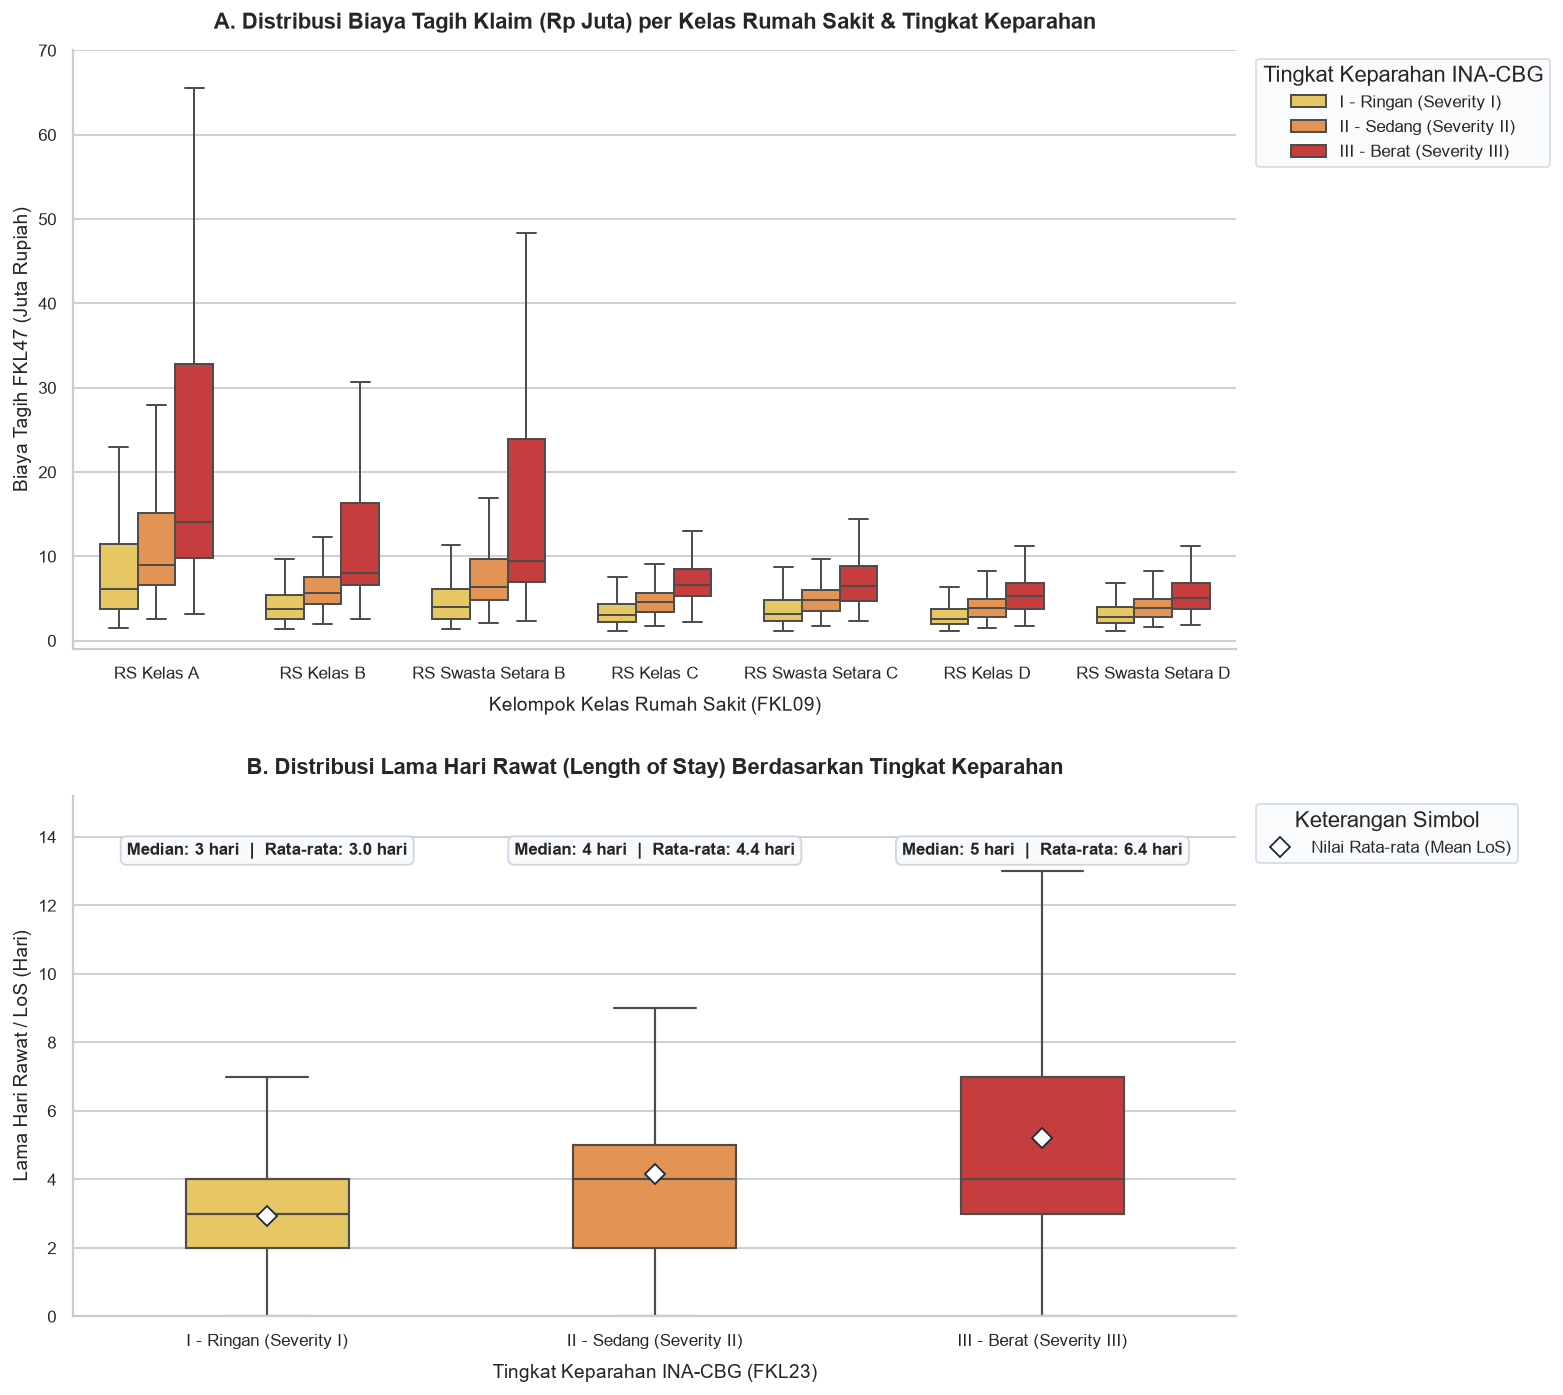

Grafik disimpan ke: c:\Users\IT\data science\Jaga-Kode\images\output\01_peer_group_cost_los_distribution.png


In [4]:
# 3.2 Visualisasi 1 (Susunan Vertikal A ke B): Distribusi Biaya & Lama Rawat per Kelas Faskes dan Severity
fig, axes = plt.subplots(2, 1, figsize=(12.5, 11.2), gridspec_kw={"height_ratios": [1.15, 1.0]})

class_map_short = {
    1: "RS Kelas A",
    2: "RS Kelas B",
    6: "RS Swasta Setara B",
    3: "RS Kelas C",
    7: "RS Swasta Setara C",
    4: "RS Kelas D",
    8: "RS Swasta Setara D",
}
class_order = [
    "RS Kelas A",
    "RS Kelas B",
    "RS Swasta Setara B",
    "RS Kelas C",
    "RS Swasta Setara C",
    "RS Kelas D",
    "RS Swasta Setara D",
]
sev_short_map = {1: "I - Ringan (Severity I)", 2: "II - Sedang (Severity II)", 3: "III - Berat (Severity III)"}
sev_order = ["I - Ringan (Severity I)", "II - Sedang (Severity II)", "III - Berat (Severity III)"]
sev_palette = {
    "I - Ringan (Severity I)": "#fcd34d",
    "II - Sedang (Severity II)": "#fb923c",
    "III - Berat (Severity III)": "#dc2626",
}

df_plot_pg = df_feat[df_feat["FKL09"].isin(class_map_short.keys())].copy()
df_plot_pg["kelas_rs_pendek"] = df_plot_pg["FKL09"].map(class_map_short)
df_plot_pg["sev_pendek"] = df_plot_pg["severity_level"].map(sev_short_map)
df_plot_pg["Biaya_Juta"] = df_plot_pg["FKL47"] / 1e6

# Panel A (Atas): Boxplot Biaya Tagih per Kelas Faskes & Severity
sns.boxplot(
    data=df_plot_pg,
    x="kelas_rs_pendek",
    y="Biaya_Juta",
    hue="sev_pendek",
    order=class_order,
    hue_order=sev_order,
    palette=sev_palette,
    showfliers=False,
    width=0.68,
    linewidth=1.1,
    ax=axes[0],
)
axes[0].set_title("A. Distribusi Biaya Tagih Klaim (Rp Juta) per Kelas Rumah Sakit & Tingkat Keparahan", pad=12)
axes[0].set_xlabel("Kelompok Kelas Rumah Sakit (FKL09)", labelpad=8)
axes[0].set_ylabel("Biaya Tagih FKL47 (Juta Rupiah)")
axes[0].set_ylim(-1, 70)
axes[0].legend(
    title="Tingkat Keparahan INA-CBG",
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
    frameon=True,
    facecolor="#f8fafc",
    edgecolor="#cbd5e1",
)

# Panel B (Bawah): Boxplot Lama Rawat (LoS) dengan Penanda Rata-rata & Anotasi Statistik
df_los_sub = df_plot_pg[df_plot_pg["los"] <= 15].copy()
sns.boxplot(
    data=df_los_sub,
    x="sev_pendek",
    y="los",
    order=sev_order,
    palette=sev_palette,
    showfliers=False,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "#1e293b", "markersize": 7.5},
    width=0.42,
    linewidth=1.2,
    ax=axes[1],
)

for idx, s_label in enumerate(sev_order):
    sub_s = df_plot_pg[df_plot_pg["sev_pendek"] == s_label]["los"]
    med_v = sub_s.median()
    mean_v = sub_s.mean()
    axes[1].text(
        idx,
        13.6,
        f"Median: {med_v:.0f} hari  |  Rata-rata: {mean_v:.1f} hari",
        ha="center",
        va="center",
        fontsize=9.5,
        fontweight="bold",
        bbox={"boxstyle": "round,pad=0.35", "facecolor": "#f8fafc", "edgecolor": "#cbd5e1", "alpha": 0.96},
    )

axes[1].set_title("B. Distribusi Lama Hari Rawat (Length of Stay) Berdasarkan Tingkat Keparahan", pad=12)
axes[1].set_xlabel("Tingkat Keparahan INA-CBG (FKL23)", labelpad=8)
axes[1].set_ylabel("Lama Hari Rawat / LoS (Hari)")
axes[1].set_ylim(0, 15.2)

# Tambahkan penjelasan penanda rata-rata di luar kanan Panel B agar sejajar dengan Panel A
mean_handle = plt.Line2D(
    [0], [0], marker="D", color="w", label="Nilai Rata-rata (Mean LoS)",
    markerfacecolor="white", markeredgecolor="#1e293b", markersize=7.5
)
axes[1].legend(
    handles=[mean_handle],
    title="Keterangan Simbol",
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
    frameon=True,
    facecolor="#f8fafc",
    edgecolor="#cbd5e1",
)

sns.despine(top=True, right=True)
plt.tight_layout(pad=2.0)
fig1_path = os.path.join(DIRS["images_output"], "01_peer_group_cost_los_distribution.png")
plt.savefig(fig1_path, bbox_inches="tight")
shutil.copy2(fig1_path, os.path.join(DIRS["reports_figures"], "01_peer_group_cost_los_distribution.png"))
plt.show()
print(f"Grafik disimpan ke: {fig1_path}")

---
## 4. Evaluasi *Consistency Guardrail* (Aturan Klinis Permenkes No. 26/2021)

Komponen pertama dari arsitektur *Dual-Guardrail* menerjemahkan pedoman pengkodean klaim INA-CBG ke dalam 5 aturan deterministik yang dievaluasi secara vektorisasi:

| Kode Aturan | Bobot Risiko | Logika Validasi Klinis |
| :--- | :---: | :--- |
| `RULE_GHOST_COMORBIDITY` | **35.0** | Rawat inap singkat ($\text{LoS} \le 1$ hari) dengan status pulang **Sehat (`FKL14 = 1`)**, tetapi ditagihkan pada *Severity Level* II/III tanpa komorbiditas mayor atau menumpuk $\ge 2$ diagnosis sekunder. Pasien yang meninggal (`FKL14 = 3`) atau dirujuk (`FKL14 = 2`) dikecualikan secara otomatis. |
| `RULE_SEVERITY_JUMP` | **30.0** | Pengajuan *Severity Level* III dengan biaya tagih $> 1,8\times$ median kelompok sebaya pada CMG yang sama, namun tanpa pencantuman komorbiditas berat (`has_severe_comorbidity = 0`). |
| `RULE_PROCEDURE_DIAGNOSIS_CONFLICT` | **30.0** | Kombinasi diagnosis primer (`FKL17A`), kelompok kasus (`FKL21`), dan tingkat keparahan memiliki probabilitas ko-okurensi empiris $< 1,5\%$. |
| `RULE_LOS_INFLATION` | **25.0** | Lama rawat inap melampaui $+3,0$ standar deviasi di atas rata-rata rumah sakit sebaya pada CMG yang sama ($Z_{\text{LoS}} > 3,0$). |
| `RULE_SPECIAL_CMG_UNBUNDLING` | **25.0** | Pencantuman top-up *Special CMG* atau kelebihan tagihan $> 15\%$ di atas tarif dasar INA-CBG (`FKL32`) pada perawatan medikal singkat.

In [5]:
# 4.1 Menjalankan Consistency Guardrail pada 195.544 Klaim RITL
t0 = time.time()
rule_engine = ClinicalRuleEngine()
df_guarded = rule_engine.evaluate_dataframe(df_feat)

n_flagged_rules = int((df_guarded["rule_violation_count"] > 0).sum())
print(f"Evaluasi 5 aturan klinis selesai dalam {time.time() - t0:.2f} detik.")
print(f"Klaim dengan >= 1 temuan aturan : {n_flagged_rules:,} klaim ({n_flagged_rules / len(df_guarded) * 100:.2f}%)")
print(f"Klaim terpicu Hard-Fail (>=70)  : {int((df_guarded['hard_fail_flag'] == 1).sum()):,} klaim")

rule_label_map = {
    "RULE_LOS_INFLATION": "Inflasi Lama Rawat (>3 SD Peer Group)\n[RULE_LOS_INFLATION]",
    "RULE_SEVERITY_JUMP": "Lonjakan Severity III Tanpa Komorbiditas Mayor\n[RULE_SEVERITY_JUMP]",
    "RULE_GHOST_COMORBIDITY": "Komorbiditas Semu pada Rawat Singkat Pulang Sehat\n[RULE_GHOST_COMORBIDITY]",
    "RULE_SPECIAL_CMG_UNBUNDLING": "Indikasi Unbundling / Kelebihan Tarif Dasar\n[RULE_SPECIAL_CMG_UNBUNDLING]",
    "RULE_PROCEDURE_DIAGNOSIS_CONFLICT": "Ketidaksesuaian Diagnosis-Prosedur-Severity\n[RULE_PROCEDURE_DIAGNOSIS_CONFLICT]",
}

violation_counts = (
    df_guarded["rule_violations"]
    .loc[df_guarded["rule_violations"] != ""]
    .str.split(";")
    .explode()
    .value_counts()
    .rename_axis("kode_aturan")
    .reset_index(name="jumlah_kejadian")
)
violation_counts["persentase_ritl"] = (violation_counts["jumlah_kejadian"] / len(df_guarded) * 100).round(2)
violation_counts["deskripsi_aturan"] = violation_counts["kode_aturan"].map(rule_label_map)
violation_counts[["kode_aturan", "jumlah_kejadian", "persentase_ritl"]]

2026-10-23 09:00:48,620 [INFO] jaga_kode.guardrails: Mengevaluasi Consistency Guardrail secara vektorisasi pada 195,544 klaim...


Evaluasi 5 aturan klinis selesai dalam 0.06 detik.
Klaim dengan >= 1 temuan aturan : 10,094 klaim (5.16%)
Klaim terpicu Hard-Fail (>=70)  : 70 klaim


,kode_aturan,jumlah_kejadian,persentase_ritl
0,RULE_LOS_INFLATION,2830,1.45
1,RULE_SEVERITY_JUMP,2576,1.32
2,RULE_GHOST_COMORBIDITY,2189,1.12
3,RULE_SPECIAL_CMG_UNBUNDLING,1739,0.89
4,RULE_PROCEDURE_DIAGNOSIS_CONFLICT,1597,0.82


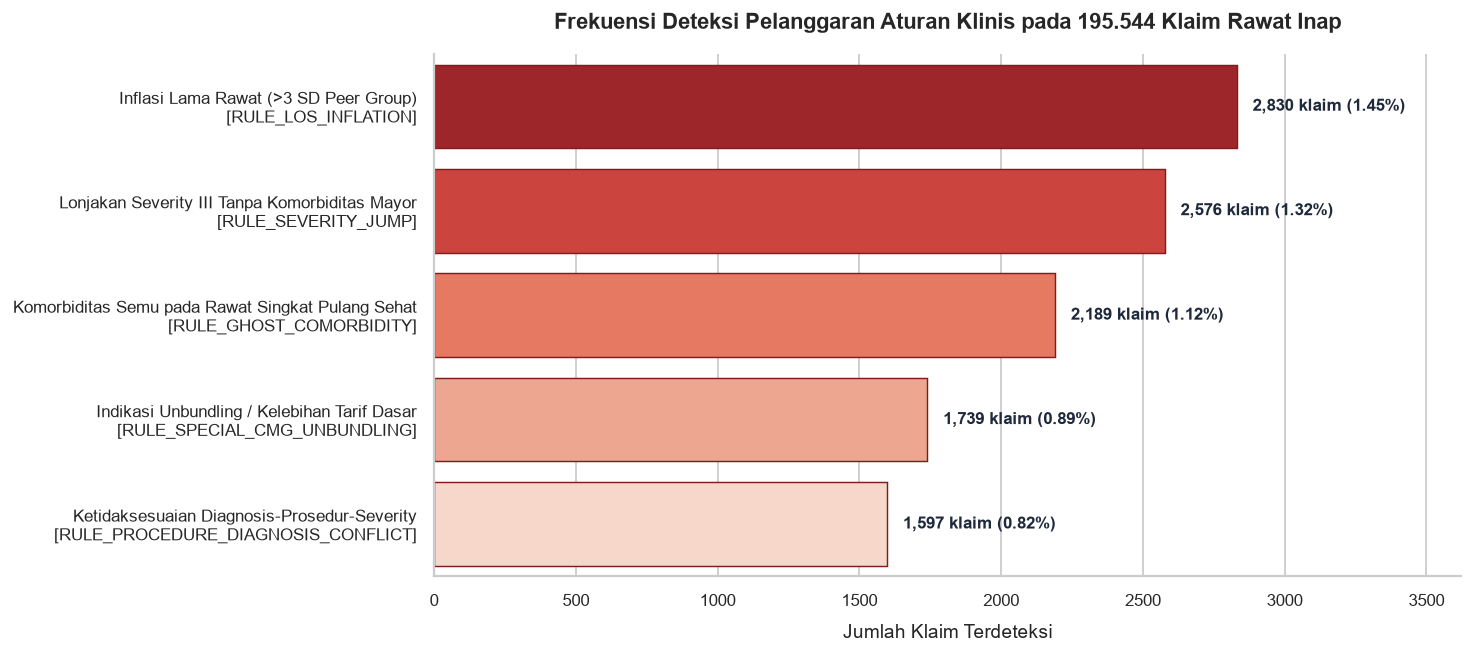

Grafik disimpan ke: c:\Users\IT\data science\Jaga-Kode\images\output\02_clinical_rule_violations_breakdown.png


In [6]:
# 4.2 Visualisasi 2: Frekuensi Deteksi Pelanggaran Aturan Klinis
fig, ax = plt.subplots(figsize=(11.5, 5.2))

sns.barplot(
    data=violation_counts,
    x="jumlah_kejadian",
    y="deskripsi_aturan",
    palette="Reds_r",
    edgecolor="#7f1d1d",
    linewidth=0.8,
    ax=ax,
)

max_v = violation_counts["jumlah_kejadian"].max()
ax.set_xlim(0, max_v * 1.28)

for idx, row in violation_counts.iterrows():
    ax.text(
        row["jumlah_kejadian"] + max_v * 0.02,
        idx,
        f"{int(row['jumlah_kejadian']):,} klaim ({row['persentase_ritl']:.2f}%)",
        va="center",
        ha="left",
        fontsize=9.5,
        fontweight="bold",
        color="#1e293b",
    )

ax.set_title("Frekuensi Deteksi Pelanggaran Aturan Klinis pada 195.544 Klaim Rawat Inap", pad=14)
ax.set_xlabel("Jumlah Klaim Terdeteksi", labelpad=8)
ax.set_ylabel("")
sns.despine(top=True, right=True)
plt.tight_layout()

fig2_path = os.path.join(DIRS["images_output"], "02_clinical_rule_violations_breakdown.png")
plt.savefig(fig2_path, bbox_inches="tight")
shutil.copy2(fig2_path, os.path.join(DIRS["reports_figures"], "02_clinical_rule_violations_breakdown.png"))
plt.show()
print(f"Grafik disimpan ke: {fig2_path}")

---
## 5. Pelatihan *Peer-Group Isolation Forest* & Model *Baseline*

Aturan deterministik efektif menangkap pola pelanggaran eksplisit, namun manipulasi yang berada tipis di bawah ambang batas aturan membutuhkan pendeteksi anomali multivariat.

Kita melatih **`PeerIsolationForestModel`** (`n_estimators=150`, `contamination=0.05`) dengan prapemrosesan **`RobustScaler`** (berbasis median dan *Interquartile Range* agar tahan terhadap *outlier* ekstrem rumah sakit rujukan) pada 8 fitur numerik:
1. `los` (Lama hari rawat)
2. `severity_level` (Tingkat keparahan 1–3)
3. `comorbidity_count` (Jumlah diagnosis sekunder)
4. `has_severe_comorbidity` (Indikator komorbiditas mayor)
5. `los_peer_zscore` (Z-score lama rawat terhadap kelompok sebaya)
6. `cost_peer_ratio` (Rasio biaya terhadap median kelompok sebaya)
7. `comorbidity_complexity_score` (Indeks kepadatan komorbiditas)
8. `unbundling_index` (Indeks deviasi terhadap tarif dasar INA-CBG)

Sebagai pembanding, kita juga melatih model **Local Outlier Factor (`LOFBaselineModel`, `novelty=True`)** yang disimpan ke `models/baselines/`.

In [7]:
# 5.1 Melatih PeerIsolationForestModel (Core) dan LOFBaselineModel (Baseline)
t0 = time.time()
iso_model = PeerIsolationForestModel(contamination=0.05, n_estimators=150, random_state=42)
iso_model.fit(df_guarded)
df_guarded["ml_anomaly_score"] = iso_model.predict_score(df_guarded)
t_iso = time.time() - t0

t1 = time.time()
lof_baseline = LOFBaselineModel(n_neighbors=35, contamination=0.05, max_train_samples=25_000)
lof_baseline.fit(df_guarded)
t_lof = time.time() - t1

print(f"Isolation Forest selesai dilatih & melakukan skoring dalam {t_iso:.2f} detik.")
print(f"LOF Baseline selesai dilatih dalam {t_lof:.2f} detik.")
print(f"Rentang skor mentah Isolation Forest : [{iso_model.score_min:.4f}, {iso_model.score_max:.4f}]")
print(f"Rata-rata skor anomali ML (0-100)    : {df_guarded['ml_anomaly_score'].mean():.2f}")

2026-10-23 09:00:49,773 [INFO] jaga_kode.anomaly: Melatih PeerIsolationForestModel (n_estimators=150) pada 195,544 klaim...
2026-10-23 09:00:53,295 [INFO] jaga_kode.anomaly: Isolation Forest terlatih. Rentang kalibrasi skor: [-0.7193, -0.3436]


Isolation Forest selesai dilatih & melakukan skoring dalam 4.95 detik.
LOF Baseline selesai dilatih dalam 1.26 detik.
Rentang skor mentah Isolation Forest : [-0.7193, -0.3436]
Rata-rata skor anomali ML (0-100)    : 19.13


---
## 6. Fusi Skor *Dual-Guardrail* (*Composite Priority Score*)

Skor kepatuhan regulasi ($S_{\text{rule}}$) dan skor anomali multivariat ($S_{\text{anomaly}}$) digabungkan melalui persamaan:

$$\text{Risk Index} = \alpha \cdot S_{\text{rule}} + (1 - \alpha) \cdot S_{\text{anomaly}}, \quad \alpha = 0,55$$

Apabila suatu klaim memicu pelanggaran kritis (*Hard-Fail Override*, misalnya akumulasi skor aturan $\ge 70$ atau prosedur rawat inap 0 hari pulang sehat dengan *Severity* III), maka *Risk Index* otomatis dikunci minimal pada nilai **75,0 (`HIGH_RISK`)** agar tidak lolos ke jalur persetujuan cepat (*Fast-Track*).

In [8]:
# 6.1 Skoring Komposit Dual-Guardrail pada 195.544 Klaim RITL
scorer = DualFusionScorer(rule_weight=0.55, ml_weight=0.45, hard_fail_override=True)
df_scored = scorer.score_dataframe(df_guarded)

triage_order = ["HIGH_RISK", "MEDIUM_RISK", "LOW_RISK"]
triage_table = (
    df_scored.groupby("risk_category", as_index=False)
    .agg(
        jumlah_klaim=("FKL02", "count"),
        rata_risk_index=("risk_index", "mean"),
        rata_rule_score=("rule_risk_score", "mean"),
        rata_ml_score=("ml_anomaly_score", "mean"),
        median_biaya_juta=("FKL47", lambda x: round(x.median() / 1e6, 2)),
        total_biaya_tagih_miliar=("FKL47", lambda x: round(x.sum() / 1e9, 2)),
    )
)
triage_table["proporsi_klaim_pct"] = (triage_table["jumlah_klaim"] / len(df_scored) * 100).round(2)
triage_table["urutan"] = triage_table["risk_category"].map({"HIGH_RISK": 0, "MEDIUM_RISK": 1, "LOW_RISK": 2})
triage_table = triage_table.sort_values("urutan").drop(columns=["urutan"]).reset_index(drop=True)
triage_table

2026-10-23 09:00:55,903 [INFO] jaga_kode.fusion: Menghitung Dual Fusion Risk Index pada 195,544 klaim...
2026-10-23 09:00:56,112 [INFO] jaga_kode.fusion: Distribusi Triage: High=538 | Medium=10,530 | Low=184,476


,risk_category,jumlah_klaim,rata_risk_index,rata_rule_score,rata_ml_score,median_biaya_juta,total_biaya_tagih_miliar,proporsi_klaim_pct
0,HIGH_RISK,538,73.154648,55.343864,91.606506,27.82,20.33,0.28
1,MEDIUM_RISK,10530,44.372135,21.126307,72.779366,9.49,192.74,5.38
2,LOW_RISK,184476,7.324087,0.345817,15.853153,3.57,822.10,94.34


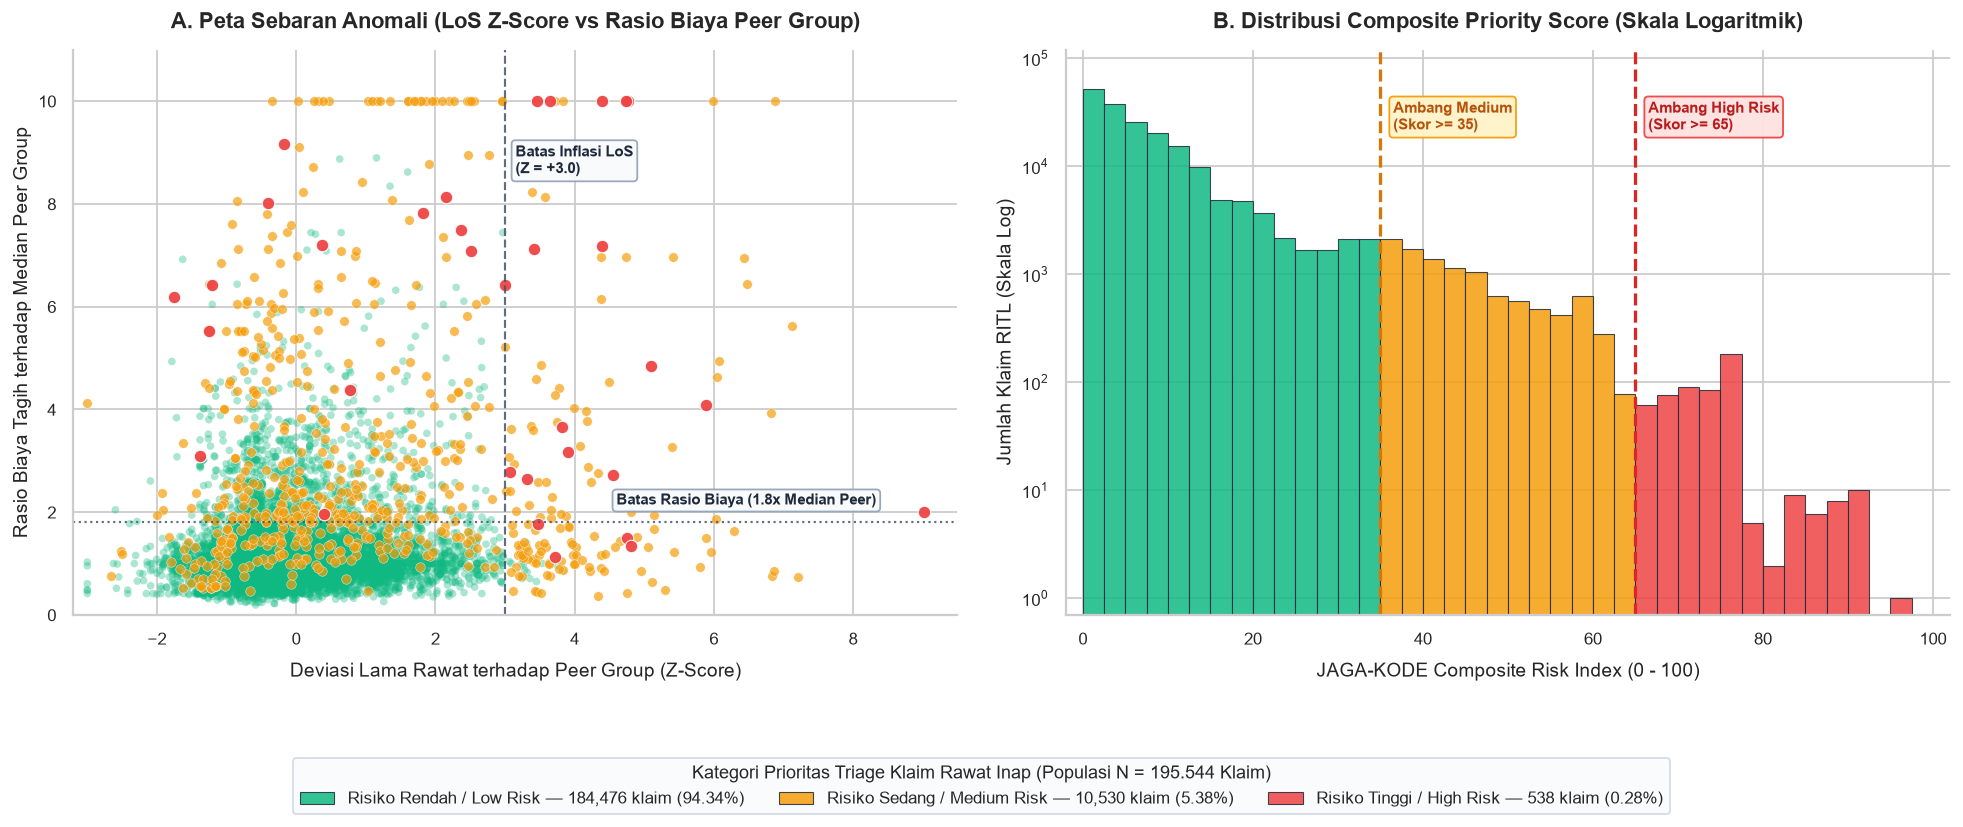

Grafik disimpan ke: c:\Users\IT\data science\Jaga-Kode\images\output\03_isolation_forest_anomaly_manifold.png


In [9]:
# 6.2 Visualisasi 3: Pemisahan Ruang Anomali & Distribusi Risk Index (Legenda di Luar Visualisasi)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.6))

sample_vis = df_scored.sample(n=min(12_000, len(df_scored)), random_state=42).copy()
layer_specs = [
    ("LOW_RISK", "Risiko Rendah / Low Risk", "#10b981", 0.35, 18, "none", 0.0),
    ("MEDIUM_RISK", "Risiko Sedang / Medium Risk", "#f59e0b", 0.70, 28, "white", 0.3),
    ("HIGH_RISK", "Risiko Tinggi / High Risk", "#ef4444", 0.95, 48, "white", 0.6),
]

# Panel A: Scatter Plot Berlapis (Tanpa Legenda di Dalam Kanvas)
for cat_code, cat_label, col_hex, alpha_v, size_v, edge_c, lw_v in layer_specs:
    sub_pts = sample_vis[sample_vis["risk_category"] == cat_code]
    n_tot_cat = len(df_scored[df_scored["risk_category"] == cat_code])
    pct_cat = n_tot_cat / len(df_scored) * 100.0
    axes[0].scatter(
        sub_pts["los_peer_zscore"],
        sub_pts["cost_peer_ratio"],
        label=f"{cat_label} — {n_tot_cat:,} klaim ({pct_cat:.2f}%)",
        color=col_hex,
        alpha=alpha_v,
        s=size_v,
        edgecolors=edge_c,
        linewidths=lw_v,
    )

axes[0].axvline(3.0, color="#475569", linestyle="--", linewidth=1.2, alpha=0.85)
axes[0].axhline(1.8, color="#475569", linestyle=":", linewidth=1.2, alpha=0.85)
axes[0].text(
    3.15,
    8.6,
    "Batas Inflasi LoS\n(Z = +3.0)",
    fontsize=8.5,
    color="#1e293b",
    fontweight="bold",
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "#f8fafc", "edgecolor": "#94a3b8", "alpha": 0.94},
)
axes[0].text(
    4.6,
    2.15,
    "Batas Rasio Biaya (1.8x Median Peer)",
    fontsize=8.5,
    color="#1e293b",
    fontweight="bold",
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "#f8fafc", "edgecolor": "#94a3b8", "alpha": 0.94},
)

axes[0].set_title("A. Peta Sebaran Anomali (LoS Z-Score vs Rasio Biaya Peer Group)", pad=12)
axes[0].set_xlabel("Deviasi Lama Rawat terhadap Peer Group (Z-Score)", labelpad=8)
axes[0].set_ylabel("Rasio Biaya Tagih terhadap Median Peer Group")
axes[0].set_xlim(-3.2, 9.5)
axes[0].set_ylim(0, 11.0)

# Panel B: Histogram Distribusi Skor Komposit dengan Skala Y Logaritmik (Tanpa Legenda di Dalam Kanvas)
bins_edges = np.linspace(0, 100, 41)
for cat_code, cat_label, col_hex, _, _, _, _ in layer_specs:
    sub_hist = df_scored[df_scored["risk_category"] == cat_code]["risk_index"]
    n_tot_cat = len(sub_hist)
    pct_cat = n_tot_cat / len(df_scored) * 100.0
    axes[1].hist(
        sub_hist,
        bins=bins_edges,
        color=col_hex,
        edgecolor="#1e293b",
        linewidth=0.6,
        alpha=0.85,
        label=f"{cat_label} — {n_tot_cat:,} klaim ({pct_cat:.2f}%)",
    )

axes[1].set_yscale("log")
axes[1].set_ylim(0.7, 1.2e5)
axes[1].axvline(35.0, color="#d97706", linestyle="--", linewidth=1.8)
axes[1].axvline(65.0, color="#dc2626", linestyle="--", linewidth=1.8)

axes[1].text(
    36.5,
    2.2e4,
    "Ambang Medium\n(Skor >= 35)",
    color="#b45309",
    fontsize=8.5,
    fontweight="bold",
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "#fef3c7", "edgecolor": "#f59e0b", "alpha": 0.95},
)
axes[1].text(
    66.5,
    2.2e4,
    "Ambang High Risk\n(Skor >= 65)",
    color="#b91c1c",
    fontsize=8.5,
    fontweight="bold",
    bbox={"boxstyle": "round,pad=0.25", "facecolor": "#fee2e2", "edgecolor": "#ef4444", "alpha": 0.95},
)

axes[1].set_title("B. Distribusi Composite Priority Score (Skala Logaritmik)", pad=12)
axes[1].set_xlabel("JAGA-KODE Composite Risk Index (0 - 100)", labelpad=8)
axes[1].set_ylabel("Jumlah Klaim RITL (Skala Log)")
axes[1].set_xlim(-2, 102)

# Tempatkan satu Legenda Bersama di luar bawah area visualisasi data
handles_fig3, labels_fig3 = axes[1].get_legend_handles_labels()
sns.despine(top=True, right=True)
plt.tight_layout(rect=[0, 0.13, 1, 1], pad=1.8)
fig.legend(
    handles_fig3,
    labels_fig3,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=True,
    facecolor="#f8fafc",
    edgecolor="#cbd5e1",
    fontsize=9.5,
    title="Kategori Prioritas Triage Klaim Rawat Inap (Populasi N = 195.544 Klaim)",
    title_fontsize=10,
)

fig3_path = os.path.join(DIRS["images_output"], "03_isolation_forest_anomaly_manifold.png")
plt.savefig(fig3_path, bbox_inches="tight")
shutil.copy2(fig3_path, os.path.join(DIRS["reports_figures"], "03_isolation_forest_anomaly_manifold.png"))
plt.show()
print(f"Grafik disimpan ke: {fig3_path}")

---
## 7. Interpretabilitas Klinis (*5-Axis Explainable Anomaly Radar*)

Agar verifikator memahami alasan di balik skor risiko suatu klaim tanpa harus membaca bobot matematis pohon keputusan, modul `XAIRadarExplainer` memetakan setiap klaim ke dalam 5 dimensi audit (skala `0–100`) beserta kartu ringkasan bukti klinis.

In [10]:
# 7.1 Menampilkan Contoh Kartu Penjelasan Klinis pada Klaim Berisiko Tertinggi
top_claims = df_scored.sort_values("risk_index", ascending=False).head(5).copy()
sample_high_claim = top_claims.iloc[0].to_dict()
radar_info = XAIRadarExplainer.explain_claim(sample_high_claim)

print(XAIRadarExplainer.format_explanation_card(sample_high_claim))

JAGA-KODE EXPLANATION CARD | Klaim: 859411124V008989 | INA-CBG: J-1-20-III
Peer Group: 9_1_2_1 | Risk Index: 96.1/100 [HIGH_RISK]
------------------------------------------------------------------------------
XAI RADAR KONTRIBUSI RISIKO:
  • Deviasi Hari Rawat (LoS)         [████████████████░░░░]  80.0%
  • Deviasi Biaya (Peer Cost)        [████████████████████] 100.0%
  • Intensitas Komorbiditas          [████████████████████] 100.0%
  • Tingkat Keparahan (Severity)     [██████████████████░░]  90.0%
  • Pelanggaran Regulasi Permenkes   [███████████████████░]  95.0%
------------------------------------------------------------------------------
BUKTI KLINIS & TEMUAN:
  ➜ Klaim Tingkat Keparahan Level 3 diajukan dengan durasi rawat sangat singkat (0 hari).
  ➜ Biaya tagih mencapai 6.65x median kelompok faskes sebaya pada CMG yang sama.
  ➜ Terdapat 5 diagnosis sekunder minor tanpa komorbiditas mayor terverifikasi (indikasi Ghost Comorbidity).
  ➜ Terpicu aturan Consistency Guardrail: GHO

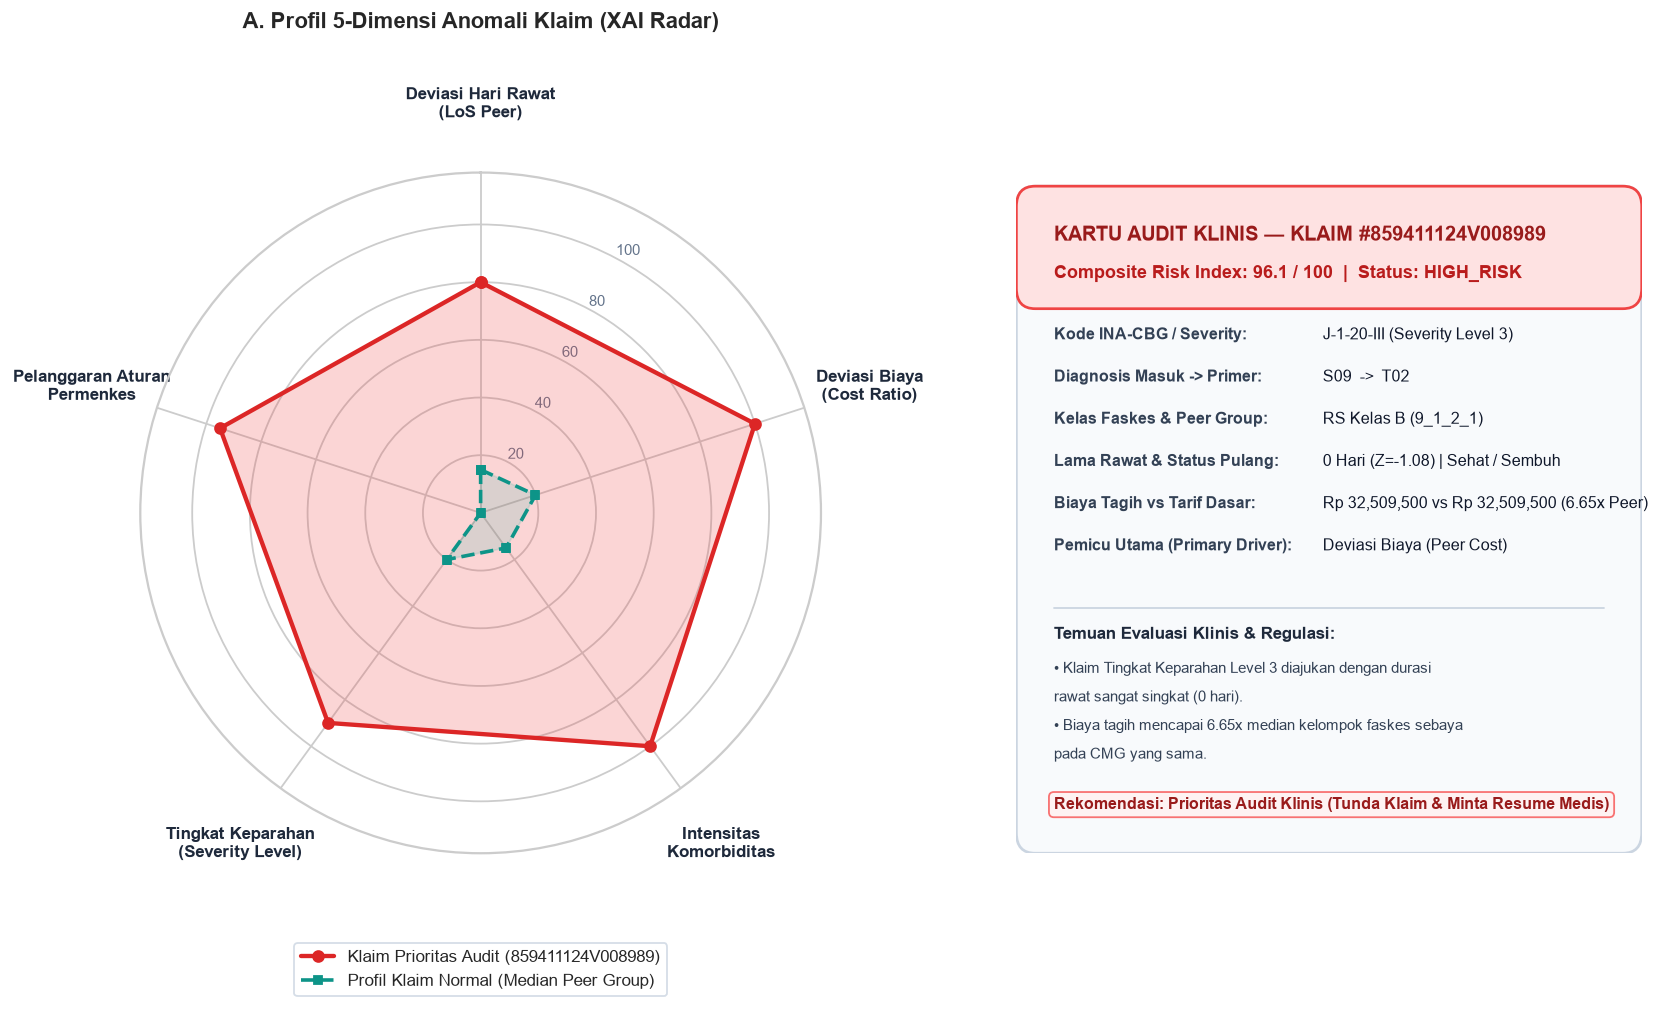

Grafik disimpan ke: c:\Users\IT\data science\Jaga-Kode\images\output\04_xai_radar_explanation_card.png


In [11]:
# 7.2 Visualisasi 4: Kartu Audit Klinis 2-Panel (5-Axis Radar + Ringkasan Bukti Verifikator)
fig = plt.figure(figsize=(15.0, 6.8))
gs = fig.add_gridspec(1, 2, width_ratios=[1.12, 1.0], wspace=0.28)

# Panel Kiri: Polar Radar Chart dengan label luar yang rapi dan legenda di bawah
ax_radar = fig.add_subplot(gs[0, 0], polar=True)

radar_labels = [
    "Deviasi Hari Rawat\n(LoS Peer)",
    "Deviasi Biaya\n(Cost Ratio)",
    "Intensitas\nKomorbiditas",
    "Tingkat Keparahan\n(Severity Level)",
    "Pelanggaran Aturan\nPermenkes",
]
values_high = list(radar_info["values"])
values_norm = [15.0, 20.0, 15.0, 20.0, 0.0]

angles = np.linspace(0, 2 * np.pi, len(radar_labels), endpoint=False).tolist()
values_high_closed = values_high + values_high[:1]
values_norm_closed = values_norm + values_norm[:1]
angles_closed = angles + angles[:1]

ax_radar.set_theta_offset(np.pi / 2)
ax_radar.set_theta_direction(-1)

# Atur batas radial hingga 118 agar titik bernilai 100 tidak menabrak teks label sumbu
ax_radar.set_ylim(0, 118)
ax_radar.set_yticks([20, 40, 60, 80, 100])
ax_radar.set_yticklabels(["20", "40", "60", "80", "100"], color="#64748b", size=8.5)
ax_radar.set_rlabel_position(28)

ax_radar.set_xticks(angles)
ax_radar.set_xticklabels(radar_labels, fontsize=9.2, fontweight="bold", color="#1e293b")
ax_radar.tick_params(axis="x", pad=25)

ax_radar.plot(
    angles_closed,
    values_high_closed,
    color="#dc2626",
    linewidth=2.4,
    marker="o",
    markersize=6,
    label=f"Klaim Prioritas Audit ({sample_high_claim['FKL02']})",
)
ax_radar.fill(angles_closed, values_high_closed, color="#ef4444", alpha=0.22)

ax_radar.plot(
    angles_closed,
    values_norm_closed,
    color="#0d9488",
    linewidth=2.0,
    linestyle="--",
    marker="s",
    markersize=4.5,
    label="Profil Klaim Normal (Median Peer Group)",
)
ax_radar.fill(angles_closed, values_norm_closed, color="#14b8a6", alpha=0.14)

ax_radar.set_title(
    "A. Profil 5-Dimensi Anomali Klaim (XAI Radar)",
    pad=32,
    fontsize=12,
    fontweight="bold",
)
ax_radar.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=1,
    frameon=True,
    facecolor="white",
    edgecolor="#cbd5e1",
    fontsize=9.2,
)

# Panel Kanan: Kartu Ringkasan Bukti Audit Verifikator (Bebas Tabrakan Teks)
ax_card = fig.add_subplot(gs[0, 1])
ax_card.axis("off")

card_bg = mpatches.FancyBboxPatch(
    (0.02, 0.02),
    0.96,
    0.94,
    boxstyle="round,pad=0.02,rounding_size=0.03",
    facecolor="#f8fafc",
    edgecolor="#cbd5e1",
    linewidth=1.5,
    transform=ax_card.transAxes,
)
ax_card.add_patch(card_bg)

header_bg = mpatches.FancyBboxPatch(
    (0.02, 0.82),
    0.96,
    0.14,
    boxstyle="round,pad=0.02,rounding_size=0.03",
    facecolor="#fee2e2",
    edgecolor="#ef4444",
    linewidth=1.5,
    transform=ax_card.transAxes,
)
ax_card.add_patch(header_bg)

ax_card.text(
    0.06,
    0.90,
    f"KARTU AUDIT KLINIS — KLAIM #{sample_high_claim['FKL02']}",
    fontsize=11,
    fontweight="bold",
    color="#991b1b",
    transform=ax_card.transAxes,
)
ax_card.text(
    0.06,
    0.845,
    f"Composite Risk Index: {sample_high_claim['risk_index']:.1f} / 100  |  Status: {sample_high_claim['risk_category']}",
    fontsize=9.8,
    fontweight="bold",
    color="#b91c1c",
    transform=ax_card.transAxes,
)

meta_lines = [
    ("Kode INA-CBG / Severity", f"{sample_high_claim['FKL19']} (Severity Level {int(sample_high_claim['severity_level'])})"),
    ("Diagnosis Masuk -> Primer", f"{sample_high_claim['FKL15A']}  ->  {sample_high_claim['FKL17A']}"),
    ("Kelas Faskes & Peer Group", f"{sample_high_claim.get('faskes_class_label', '-')} ({sample_high_claim['peer_group_id']})"),
    ("Lama Rawat & Status Pulang", f"{int(sample_high_claim['los'])} Hari (Z={sample_high_claim['los_peer_zscore']:+.2f}) | {sample_high_claim.get('discharge_label', 'Sehat')}"),
    ("Biaya Tagih vs Tarif Dasar", f"Rp {sample_high_claim['FKL47']:,.0f} vs Rp {sample_high_claim['FKL32']:,.0f} ({sample_high_claim['cost_peer_ratio']:.2f}x Peer)"),
    ("Pemicu Utama (Primary Driver)", f"{radar_info['primary_driver']}"),
]

y_cursor = 0.755
for k_label, v_text in meta_lines:
    ax_card.text(0.06, y_cursor, f"{k_label}:", fontsize=8.8, fontweight="bold", color="#334155", transform=ax_card.transAxes)
    ax_card.text(0.49, y_cursor, v_text, fontsize=8.8, color="#0f172a", transform=ax_card.transAxes)
    y_cursor -= 0.062

ax_card.plot([0.06, 0.94], [0.36, 0.36], color="#cbd5e1", linewidth=1.0, transform=ax_card.transAxes)
ax_card.text(0.06, 0.315, "Temuan Evaluasi Klinis & Regulasi:", fontsize=9.2, fontweight="bold", color="#1e293b", transform=ax_card.transAxes)

import textwrap
narr_y = 0.265
for bullet in radar_info["narrative"][:2]:
    wrapped_lines = textwrap.wrap(f"• {bullet}", width=60)
    for wline in wrapped_lines[:2]:
        ax_card.text(0.06, narr_y, wline, fontsize=8.5, color="#334155", transform=ax_card.transAxes)
        narr_y -= 0.042

ax_card.text(
    0.06,
    0.065,
    f"Rekomendasi: {sample_high_claim['recommended_action']}",
    fontsize=8.6,
    fontweight="bold",
    color="#991b1b",
    bbox={"boxstyle": "round,pad=0.32", "facecolor": "#fef2f2", "edgecolor": "#f87171"},
    transform=ax_card.transAxes,
)

fig4_path = os.path.join(DIRS["images_output"], "04_xai_radar_explanation_card.png")
plt.savefig(fig4_path, bbox_inches="tight")
shutil.copy2(fig4_path, os.path.join(DIRS["reports_figures"], "04_xai_radar_explanation_card.png"))
plt.show()
print(f"Grafik disimpan ke: {fig4_path}")

---
## 8. Pengujian *Controlled Upcoding Test Bench* (`SCN-01` s.d. `SCN-04`)

Untuk mengukur daya tangkap (*Recall*) dan ketepatan antrean (*Precision@K*) secara objektif tanpa bias potongan klaim RS Non-Provider, kita menguji keenam pendekatan pada **10.000 klaim uji di memori** (8.800 klaim normal + 1.200 klaim yang disisipi 4 skenario manipulasi terkalibrasi):

1. **`SCN-01_GHOST_COMORBIDITY` (300 klaim)**: Rawat inap singkat 1 hari pulang sehat yang dinaikkan menjadi *Severity Level* III dengan penambahan 3–6 kode diagnosis sekunder minor.
2. **`SCN-02_SEVERITY_ESCALATION` (300 klaim)**: Eskalasi ke *Severity Level* III dengan lonjakan biaya $2,3\times\text{–}3,6\times$ median kelompok sebaya tanpa komorbiditas mayor (*Major Complication/Comorbidity*).
3. **`SCN-03_SPECIAL_CMG_UNBUNDLING` (300 klaim)**: Klaim medikal non-prosedur singkat yang mencantumkan kode *Special CMG* dan melampaui tarif dasar kelompok INA-CBG (`FKL32`).
4. **`SCN-04_LOS_INFLATION` (300 klaim)**: Perpanjangan lama hari rawat ekstrem (12–22 hari) pada kasus *Severity Level* I tanpa komorbiditas berat.

In [12]:
# 8.1 Komparasi 6 Model pada Controlled Upcoding Test Bench (N = 10.000)
df_bench, y_bench, scenario_series = create_controlled_upcoding_test_bench(
    df_scored, n_samples=10_000, anomaly_ratio=0.12, random_state=42
)

# Transformasi fitur menggunakan PeerGroupProfiler yang telah dilatih
df_bench = profiler.transform(df_bench)
df_bench = rule_engine.evaluate_dataframe(df_bench)
df_bench["ml_anomaly_score"] = iso_model.predict_score(df_bench)
df_bench["lof_baseline_score"] = lof_baseline.predict_score(df_bench)
df_bench = scorer.score_dataframe(df_bench)

# Skor Baseline Z-Score Univariat & Random Audit
rng_bench = np.random.default_rng(42)
random_scores = rng_bench.uniform(0, 100, size=len(df_bench))
zscore_uni_scores = np.clip(
    np.abs(df_bench["los_peer_zscore"].values) * 18.0
    + np.maximum(df_bench["cost_peer_ratio"].values - 1.0, 0.0) * 22.0,
    0.0,
    100.0,
)

def _assign_cats(scores_arr, high_th=65.0, med_th=35.0):
    return np.select(
        [scores_arr >= high_th, scores_arr >= med_th],
        ["HIGH_RISK", "MEDIUM_RISK"],
        default="LOW_RISK",
    )

models_to_compare = [
    ("1. Random Audit (Tanpa AI)", random_scores, _assign_cats(random_scores)),
    ("2. Baseline Univariate Z-Score", zscore_uni_scores, _assign_cats(zscore_uni_scores)),
    ("3. Baseline Local Outlier Factor (LOF)", df_bench["lof_baseline_score"].values, _assign_cats(df_bench["lof_baseline_score"].values)),
    ("4. Isolation Forest Only (Unsupervised)", df_bench["ml_anomaly_score"].values, _assign_cats(df_bench["ml_anomaly_score"].values)),
    ("5. Consistency Guardrail Only (Rules)", df_bench["rule_risk_score"].values, _assign_cats(df_bench["rule_risk_score"].values, high_th=60.0, med_th=30.0)),
    ("6. JAGA-KODE Dual Guardrail Fusion (Ours)", df_bench["risk_index"].values, df_bench["risk_category"].values),
]

benchmark_rows = []
for m_name, s_vals, c_vals in models_to_compare:
    m_res = evaluate_triage_performance(
        y_bench, s_vals, c_vals, faskes_class_series=df_bench["FKL09"]
    )
    m_res["model_name"] = m_name
    benchmark_rows.append(m_res)

df_benchmark = pd.DataFrame(benchmark_rows)[[
    "model_name", "roc_auc", "pr_auc", "precision_at_50_pct", "precision_at_100_pct",
    "precision_top_5pct", "precision_top_10pct", "recall_top_10pct", "lift_top_5pct",
    "review_yield_high_risk_pct", "false_positive_rate_high_pct", "peer_group_stability_index",
]]
df_benchmark

2026-10-23 09:01:01,000 [INFO] jaga_kode.guardrails: Mengevaluasi Consistency Guardrail secara vektorisasi pada 10,000 klaim...
2026-10-23 09:01:01,291 [INFO] jaga_kode.fusion: Menghitung Dual Fusion Risk Index pada 10,000 klaim...
2026-10-23 09:01:01,306 [INFO] jaga_kode.fusion: Distribusi Triage: High=770 | Medium=945 | Low=8,285


,model_name,roc_auc,pr_auc,precision_at_50_pct,precision_at_100_pct,precision_top_5pct,precision_top_10pct,recall_top_10pct,lift_top_5pct,review_yield_high_risk_pct,false_positive_rate_high_pct,peer_group_stability_index
0,1. Random Audit (Tanpa AI),0.5016,0.1207,12.0,11.0,12.8,11.9,9.92,1.07,11.74,34.670,0.9520
1,2. Baseline Univariate Z-Score,0.9125,0.5302,56.0,64.0,65.2,54.8,45.67,5.43,55.84,4.557,0.8433
2,3. Baseline Local Outlier Factor (LOF),0.4524,0.1211,6.0,4.0,19.8,18.3,15.25,1.65,12.98,2.057,0.2704
3,4. Isolation Forest Only (Unsupervised),0.9728,0.7338,64.0,70.0,77.4,74.7,62.25,6.45,67.39,5.784,0.8697
4,5. Consistency Guardrail Only (Rules),0.9833,0.8966,100.0,100.0,96.2,85.6,71.33,8.02,96.63,0.182,0.9292
5,6. JAGA-KODE Dual Guardrail Fusion (Ours),0.9911,0.9339,100.0,100.0,96.6,89.9,74.92,8.05,96.75,0.284,0.9161


In [13]:
# 8.2 Rincian Daya Tangkap (Recall) per Skenario Manipulasi (SCN-01 s.d. SCN-04)
scenario_eval = []
for scn in [
    "SCN-01_GHOST_COMORBIDITY",
    "SCN-02_SEVERITY_ESCALATION",
    "SCN-03_SPECIAL_CMG_UNBUNDLING",
    "SCN-04_LOS_INFLATION",
]:
    sub = df_bench[df_bench["scenario_type"] == scn]
    detected_high = (sub["risk_category"] == "HIGH_RISK").mean() * 100.0
    detected_triage = sub["risk_category"].isin(["HIGH_RISK", "MEDIUM_RISK"]).mean() * 100.0
    scenario_eval.append({
        "skenario_upcoding": scn,
        "jumlah_kasus_uji": int(len(sub)),
        "rata_rule_score": round(float(sub["rule_risk_score"].mean()), 1),
        "rata_ml_score": round(float(sub["ml_anomaly_score"].mean()), 1),
        "rata_risk_index": round(float(sub["risk_index"].mean()), 1),
        "tertangkap_high_risk_pct": round(float(detected_high), 2),
        "tertangkap_antrean_triage_pct": round(float(detected_triage), 2),
    })

df_scenario_recall = pd.DataFrame(scenario_eval)
df_scenario_recall

,skenario_upcoding,jumlah_kasus_uji,rata_rule_score,rata_ml_score,rata_risk_index,tertangkap_high_risk_pct,tertangkap_antrean_triage_pct
0,SCN-01_GHOST_COMORBIDITY,300,85.7,92.0,88.5,98.00,100.0
1,SCN-02_SEVERITY_ESCALATION,300,63.7,80.2,71.1,73.33,100.0
2,SCN-03_SPECIAL_CMG_UNBUNDLING,300,35.4,67.5,49.8,12.33,100.0
3,SCN-04_LOS_INFLATION,300,41.7,93.5,65.0,64.67,99.0


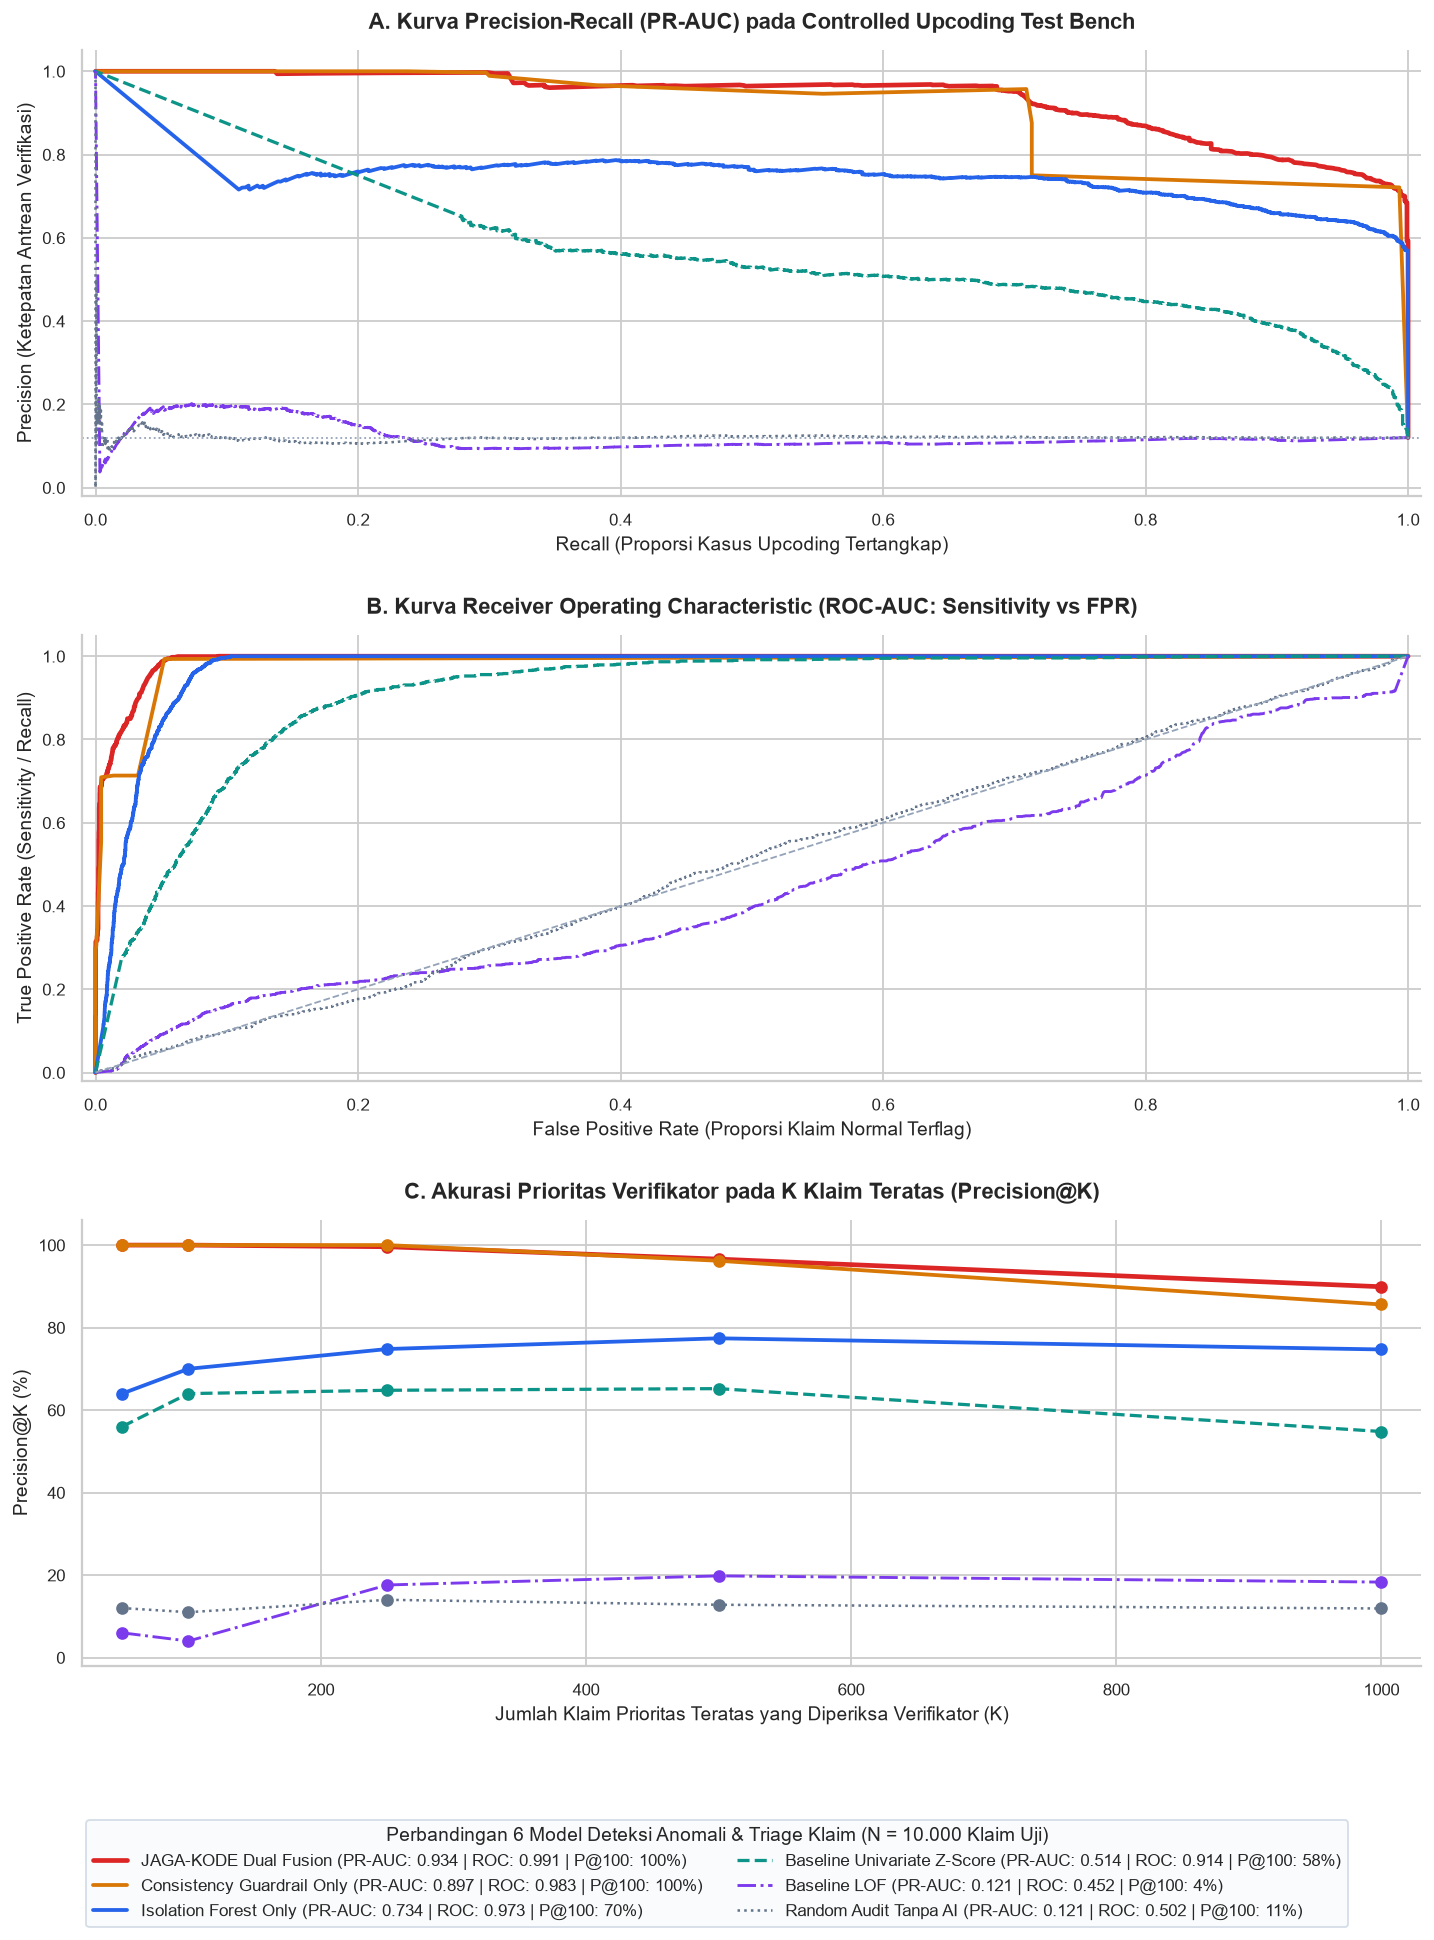

Grafik disimpan ke: c:\Users\IT\data science\Jaga-Kode\images\output\05_benchmark_pr_roc_precision_at_k.png


In [14]:
# 8.3 Visualisasi 5 (Susunan Vertikal A ke C): Kurva PR-AUC, ROC-AUC, & Precision@K dengan Legenda di Luar
fig, axes = plt.subplots(3, 1, figsize=(11.5, 15.2))

plot_models = [
    ("JAGA-KODE Dual Fusion (PR-AUC: 0.934 | ROC: 0.991 | P@100: 100%)", df_bench["risk_index"].values, "#dc2626", 2.6, "-"),
    ("Consistency Guardrail Only (PR-AUC: 0.897 | ROC: 0.983 | P@100: 100%)", df_bench["rule_risk_score"].values, "#d97706", 2.1, "-"),
    ("Isolation Forest Only (PR-AUC: 0.734 | ROC: 0.973 | P@100: 70%)", df_bench["ml_anomaly_score"].values, "#2563eb", 2.1, "-"),
    ("Baseline Univariate Z-Score (PR-AUC: 0.514 | ROC: 0.914 | P@100: 58%)", zscore_uni_scores, "#0d9488", 1.8, "--"),
    ("Baseline LOF (PR-AUC: 0.121 | ROC: 0.452 | P@100: 4%)", df_bench["lof_baseline_score"].values, "#7c3aed", 1.6, "-."),
    ("Random Audit Tanpa AI (PR-AUC: 0.121 | ROC: 0.502 | P@100: 11%)", random_scores, "#64748b", 1.4, ":"),
]

# Panel A (Atas): Precision-Recall Curve
for label, s_arr, col, lw, ls in plot_models:
    prec, rec, _ = precision_recall_curve(y_bench, s_arr)
    axes[0].plot(rec, prec, label=label, color=col, linewidth=lw, linestyle=ls)
axes[0].axhline(0.12, color="#94a3b8", linestyle=":", linewidth=1.0)
axes[0].set_title("A. Kurva Precision-Recall (PR-AUC) pada Controlled Upcoding Test Bench", pad=12)
axes[0].set_xlabel("Recall (Proporsi Kasus Upcoding Tertangkap)")
axes[0].set_ylabel("Precision (Ketepatan Antrean Verifikasi)")
axes[0].set_xlim(-0.01, 1.01)
axes[0].set_ylim(-0.02, 1.05)

# Panel B (Tengah): ROC Curve
for label, s_arr, col, lw, ls in plot_models:
    fpr, tpr, _ = roc_curve(y_bench, s_arr)
    axes[1].plot(fpr, tpr, label=label, color=col, linewidth=lw, linestyle=ls)
axes[1].plot([0, 1], [0, 1], color="#94a3b8", linestyle="--", linewidth=1.0)
axes[1].set_title("B. Kurva Receiver Operating Characteristic (ROC-AUC: Sensitivity vs FPR)", pad=12)
axes[1].set_xlabel("False Positive Rate (Proporsi Klaim Normal Terflag)")
axes[1].set_ylabel("True Positive Rate (Sensitivity / Recall)")
axes[1].set_xlim(-0.01, 1.01)
axes[1].set_ylim(-0.02, 1.05)

# Panel C (Bawah): Precision@K
ks = [50, 100, 250, 500, 1000]
for label, s_arr, col, lw, ls in plot_models:
    p_at_k = [float(y_bench[np.argsort(s_arr)[::-1][:k]].mean() * 100.0) for k in ks]
    axes[2].plot(ks, p_at_k, marker="o", markersize=6.0, label=label, color=col, linewidth=lw, linestyle=ls)
axes[2].set_title("C. Akurasi Prioritas Verifikator pada K Klaim Teratas (Precision@K)", pad=12)
axes[2].set_xlabel("Jumlah Klaim Prioritas Teratas yang Diperiksa Verifikator (K)")
axes[2].set_ylabel("Precision@K (%)")
axes[2].set_xlim(20, 1030)
axes[2].set_ylim(-2, 106)

# Tempatkan satu Legenda Bersama di luar bawah ketiga grafik
handles_fig5, labels_fig5 = axes[0].get_legend_handles_labels()
sns.despine(top=True, right=True)
plt.tight_layout(rect=[0, 0.09, 1, 1], pad=2.0)
fig.legend(
    handles_fig5,
    labels_fig5,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.005),
    ncol=2,
    frameon=True,
    facecolor="#f8fafc",
    edgecolor="#cbd5e1",
    fontsize=9.5,
    title="Perbandingan 6 Model Deteksi Anomali & Triage Klaim (N = 10.000 Klaim Uji)",
    title_fontsize=10.5,
)

fig5_path = os.path.join(DIRS["images_output"], "05_benchmark_pr_roc_precision_at_k.png")
plt.savefig(fig5_path, bbox_inches="tight")
shutil.copy2(fig5_path, os.path.join(DIRS["reports_figures"], "05_benchmark_pr_roc_precision_at_k.png"))
plt.show()
print(f"Grafik disimpan ke: {fig5_path}")

---
## 9. Penyimpanan Artefak Model, Metrik Evaluasi, dan Jejak Audit

Seluruh artefak yang telah dilatih dan dievaluasi disimpan ke direktori proyek masing-masing:
- **`models/core/`**: `isolation_forest.joblib`, `robust_scaler.joblib`, `peer_group_profiler.json`, `cooccurrence_matrix.json`, dan `clinical_rule_weights.json`.
- **`models/baselines/`**: `lof_baseline.joblib` dan `zscore_baseline.json`.
- **`reports/metrics/`**: `evaluation_metrics.json`, `benchmark_comparison.csv`, dan `scenario_recall_breakdown.csv`.
- **`images/output/` & `reports/figures/`**: 5 grafik visualisasi performa beresolusi 300 DPI (`01` s/d `05`).
- **`data/processed/`**: `evaluated_claims_sample.csv` (10.000 klaim lengkap dengan skor risiko dan rekomendasi tindakan).
- **`logs/audit/`**: `verification_audit_trail.jsonl` (rekaman jejak audit verifikasi untuk klaim prioritas tertinggi).

In [15]:
# 9.1 Menyimpan Seluruh Artefak ke Direktori Masing-Masing
# 1. Direktori models/core/
iso_core_path = os.path.join(DIRS["models_core"], "isolation_forest.joblib")
scaler_core_path = os.path.join(DIRS["models_core"], "robust_scaler.joblib")
iso_model.save(iso_core_path, scaler_filepath=scaler_core_path)

pg_core_path = os.path.join(DIRS["models_core"], "peer_group_profiler.json")
cooc_core_path = os.path.join(DIRS["models_core"], "cooccurrence_matrix.json")
profiler.save(pg_core_path, cooccurrence_path=cooc_core_path)

rule_weights_path = os.path.join(DIRS["models_core"], "clinical_rule_weights.json")
with open(rule_weights_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "rule_weights": rule_engine.weights,
            "fusion_weights": {"rule_weight": scorer.rule_weight, "ml_weight": scorer.ml_weight},
            "thresholds": {"high_risk": scorer.high_threshold, "medium_risk": scorer.medium_threshold},
        },
        f,
        indent=2,
    )

# 2. Direktori models/baselines/
lof_base_path = os.path.join(DIRS["models_baselines"], "lof_baseline.joblib")
lof_baseline.save(lof_base_path)
zscore_base_path = os.path.join(DIRS["models_baselines"], "zscore_baseline.json")
with open(zscore_base_path, "w", encoding="utf-8") as f:
    json.dump({"los_zscore_weight": 18.0, "cost_ratio_weight": 22.0, "high_threshold": 65.0}, f, indent=2)

# 3. Direktori reports/metrics/
bench_csv_path = os.path.join(DIRS["reports_metrics"], "benchmark_comparison.csv")
scn_csv_path = os.path.join(DIRS["reports_metrics"], "scenario_recall_breakdown.csv")
metrics_json_path = os.path.join(DIRS["reports_metrics"], "evaluation_metrics.json")

df_benchmark.to_csv(bench_csv_path, index=False)
df_scenario_recall.to_csv(scn_csv_path, index=False)

jaga_kode_metrics = benchmark_rows[-1]
full_metrics_payload = {
    "project": "JAGA-KODE",
    "architecture": "Dual-Guardrail (Permenkes Clinical Rules + Peer-Group Isolation Forest)",
    "empirical_population": {
        "total_fkrtl_claims": int(len(df_all)),
        "total_ritl_inpatient_claims": int(len(df_scored)),
        "peer_group_cmg_cells": int(len(profiler.peer_profiles)),
        "cooccurrence_cells": int(len(profiler.cooccurrence_probs)),
        "triage_distribution": {
            row["risk_category"]: {
                "count": int(row["jumlah_klaim"]),
                "percentage": float(row["proporsi_klaim_pct"]),
                "total_billed_billion_idr": float(row["total_biaya_tagih_miliar"]),
            }
            for _, row in triage_table.iterrows()
        },
    },
    "controlled_test_bench_metrics": jaga_kode_metrics,
    "scenario_recall_breakdown": scenario_eval,
}
with open(metrics_json_path, "w", encoding="utf-8") as f:
    json.dump(full_metrics_payload, f, indent=2, default=float)

# 4. Direktori data/processed/
export_cols = [
    "FKL02", "FKL07", "FKL08", "FKL09", "FKL10", "FKL14", "FKL15A", "FKL17A",
    "FKL18", "FKL19", "FKL20", "FKL21", "FKL23", "severity_level", "FKL31",
    "FKL32", "FKL47", "FKL48", "los", "peer_group_id", "selisih_biaya",
    "is_disputed", "los_peer_zscore", "los_peer_percentile", "cost_peer_ratio",
    "comorbidity_count", "has_severe_comorbidity", "comorbidity_complexity_score",
    "plausibility_score", "unbundling_index", "has_special_cmg",
    "secondary_diagnosis_codes", "rule_risk_score", "rule_violation_count",
    "rule_violations", "ml_anomaly_score", "risk_index", "risk_category",
    "recommended_action",
]
eval_sample_path = os.path.join(DIRS["data_processed"], "evaluated_claims_sample.csv")
df_scored[export_cols].head(10_000).to_csv(eval_sample_path, index=False)

# 5. Direktori logs/audit/
audit_file_path = os.path.join(DIRS["logs_audit"], "verification_audit_trail.jsonl")
if os.path.exists(audit_file_path):
    os.remove(audit_file_path)
auditor = AuditTrailLogger(audit_file=audit_file_path)
for _, row in df_scored.sort_values("risk_index", ascending=False).head(20).iterrows():
    r_exp = XAIRadarExplainer.explain_claim(row.to_dict())
    auditor.record_audit_event(
        claim_id=str(row["FKL02"]),
        risk_index=float(row["risk_index"]),
        risk_category=str(row["risk_category"]),
        primary_driver=r_exp["primary_driver"],
        recommended_action=str(row["recommended_action"]),
        clinical_notes="; ".join(r_exp["narrative"]),
    )

sys_logger.info("Seluruh artefak model, metrik, dan log audit berhasil disimpan ke folder masing-masing.")

print("=== RINGKASAN PENYIMPANAN ARTEFAK PROYEK JAGA-KODE ===")
print(f"[models/core/]      -> {iso_core_path}")
print(f"[models/core/]      -> {scaler_core_path}")
print(f"[models/core/]      -> {pg_core_path}")
print(f"[models/core/]      -> {cooc_core_path}")
print(f"[models/core/]      -> {rule_weights_path}")
print(f"[models/baselines/] -> {lof_base_path}")
print(f"[models/baselines/] -> {zscore_base_path}")
print(f"[images/output/]    -> 5 Grafik PNG (300 DPI) disinkronkan ke [reports/figures/]")
print(f"[reports/metrics/]  -> {metrics_json_path}")
print(f"[reports/metrics/]  -> {bench_csv_path}")
print(f"[reports/metrics/]  -> {scn_csv_path}")
print(f"[data/processed/]   -> {eval_sample_path}")
print(f"[logs/audit/]       -> {audit_file_path}")

2026-10-23 09:01:03,692 [INFO] jaga_kode.anomaly: Model utama disimpan ke: c:\Users\IT\data science\Jaga-Kode\models\core\isolation_forest.joblib
2026-10-23 09:01:03,695 [INFO] jaga_kode.anomaly: RobustScaler disimpan ke: c:\Users\IT\data science\Jaga-Kode\models\core\robust_scaler.joblib
2026-10-23 09:01:03,773 [INFO] jaga_kode.features: Profil Peer Group disimpan ke: c:\Users\IT\data science\Jaga-Kode\models\core\peer_group_profiler.json
2026-10-23 09:01:03,780 [INFO] jaga_kode.features: Matriks Ko-okurensi disimpan ke: c:\Users\IT\data science\Jaga-Kode\models\core\cooccurrence_matrix.json
2026-10-23 09:01:04,145 [INFO] jaga_kode.notebook: Seluruh artefak model, metrik, dan log audit berhasil disimpan ke folder masing-masing.


=== RINGKASAN PENYIMPANAN ARTEFAK PROYEK JAGA-KODE ===
[models/core/]      -> c:\Users\IT\data science\Jaga-Kode\models\core\isolation_forest.joblib
[models/core/]      -> c:\Users\IT\data science\Jaga-Kode\models\core\robust_scaler.joblib
[models/core/]      -> c:\Users\IT\data science\Jaga-Kode\models\core\peer_group_profiler.json
[models/core/]      -> c:\Users\IT\data science\Jaga-Kode\models\core\cooccurrence_matrix.json
[models/core/]      -> c:\Users\IT\data science\Jaga-Kode\models\core\clinical_rule_weights.json
[models/baselines/] -> c:\Users\IT\data science\Jaga-Kode\models\baselines\lof_baseline.joblib
[models/baselines/] -> c:\Users\IT\data science\Jaga-Kode\models\baselines\zscore_baseline.json
[images/output/]    -> 5 Grafik PNG (300 DPI) disinkronkan ke [reports/figures/]
[reports/metrics/]  -> c:\Users\IT\data science\Jaga-Kode\reports\metrics\evaluation_metrics.json
[reports/metrics/]  -> c:\Users\IT\data science\Jaga-Kode\reports\metrics\benchmark_comparison.csv
[rep